# 41 — Question 2: the design space

What is an eVTOL design made of, and where do designs concentrate?

Sub-questions 2.1, 2.2, 2.3 of the Labelling Analysis (2026-09-30). Every path comes from `labelling_analysis.yaml`; equations come from `lib/`, figures and tables from `viz/`.

This notebook reproduces every figure, table and number of chapter 2 of the 45-page document, and compares them with it (`viz.checks`). Nothing in chapter 2 uses the five-class fold (the archetype sets read the twelve classes), so the class fold of 2026-10-01 (Stopped/Slowed Rotor Wing into Lift + Cruise) moves no number here; the only differences from the document's tables are the display names of 2026-09-28 (Tilt Rotor is printed Tilt Propulsor, propulsive unit is printed propulsor unit), which `viz.checks` maps through `rename`.

Outputs are written to `<output>/q2_design_space/` (figures: pdf, png, csv, json; tables: csv, json). Regenerate this notebook with `python3 notebooks/_build/build_41.py`.

### Chapter 2 — The design space: what is an eVTOL design made of, and where do designs concentrate?

Chapter 3 asks whether eVTOL designs converge. That question needs two things first: what a design is, and where the designs sit today. This chapter supplies both, in three steps.

- **2.1: what a design is made of.** The label fields are read one at a time, to find the few that tell one aircraft from another; the propulsion, where most of the variety lies, is read per architecture class.
- **2.2: how designs are grouped.** The fields that vary are combined into **archetypes**, and the archetype sets at which every later count is made are fixed, among them the Lift + Cruise + CVT* family that the dominant-design test of chapter 3 reads.
- **2.3: where designs concentrate.** The archetypes are placed on a map of where the recent aircraft sit and how many firms file them, and the labelled dataset is asked whether new archetypes are still appearing.

Every result of chapter 3 (a share that grows, a design that dominates or does not, a class that settles) is a statement about archetypes in a named archetype set, so it cannot be read before this chapter. The propulsion vocabulary the chapter uses comes first.

**The propulsion vocabulary.**

| term | what it is |
|---|---|
| **propulsor type** | one set of like propulsor units in one place, sharing the same tilt, duct and fold |
| **tilting set** | each part of the aircraft that swivels its propulsors as one: a tilting propulsor type, a tilting wing panel, a tilting boom group or a tilting tail |
| **boom group** | booms recorded together because they share the same attachment and tilt |
| **control propulsor** | a small propulsor giving attitude or yaw authority only, not lift or cruise thrust |
| **propulsor-unit band** | the propulsor-unit count in five bands: 1-3, 4, 5-6, 7-8, 9 or more |

*Group* is used only for a boom group.

## 0. Setup: paths and the analysis unit

The table lists every input this notebook can read, whether it exists and when it last changed. The load raises if a required input is missing.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from viz import config, data
cfg = config.load()
config.show(cfg)[['group', 'key', 'exists', 'modified', 'size', 'path']]

,group,key,exists,modified,size,path
0,root,labelled,True,2026-09-25 14:05,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED
1,root,evtolnews,True,2026-09-22 15:12,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS
2,root,reference,True,2026-09-30 18:42,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
3,root,output,True,2026-10-01 19:52,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
4,labelled_dataset,aircraft_labels,True,2026-10-01 16:38,"2,211 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
5,labelled_dataset,figure_labels,True,2026-10-01 16:38,"2,953 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
6,labelled_dataset,label_dictionary,True,2026-10-01 16:38,46 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
7,other_inputs,patent_facts,True,2026-10-01 16:37,"1,595 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
8,other_inputs,trl_per_aircraft,True,2026-09-22 14:41,224 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
9,other_inputs,evtolnews_aircraft,True,2026-09-17 19:41,991 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS/0_source/aircraft.csv


The analysis unit is the representative primary aircraft: wizard-approved, passes the domain gate (no UAV/not-electric/STOL-only tag), one row per aircraft. Counts below must match the document.

In [2]:
ds = data.load_dataset(cfg)
pd.Series(ds.counts, name='count').to_frame()

,count
patents_acquired,1639
patents_wizard_approved,1109
patents_approved,879
patents_gated_out,230
variants_gated_out,257
primary_variants_gated_out,171
patents_analysis,543
approved_variants,963
primary_approved_variants,627
approved_figures,1538


### Tools used below

`frames.base` is the per-aircraft analysis frame (627 rows); `lib` holds every equation; `viz.checks` compares with the document. `verify` runs one table check and keeps its summary for the final overview; `numbers_check` does the same for the quoted numbers.

In [3]:
import inspect
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import Bbox
from IPython.display import display
from viz import frames, style, plots, save, checks
from lib import diversity, concentration, dominant_design

style.apply(cfg)
import thesis_style as ts; ts.use()                        # thesis base style, after the viz style
v = frames.base(ds, cfg)                                   # one row per unique aircraft (627)
WIN_NAMES = list(cfg.analysis['windows'])
W, _ = style.size(cfg, 'full')
SEED = cfg.analysis['random_seed']
pct = lambda x: f"{x:.0%}".replace('%', ' %')              # 0.53 -> '53 %'
CHECKS, NUMBERS = [], []                                   # summaries kept for the overview at the end

def verify(frame, ref, name=None, **kw):
    r = checks.table(frame, ref, cfg, name=name, **kw)
    CHECKS.append(r)
    display(r.T.rename(columns={0: name or ref}))
    d = checks.detail(r)
    if len(d):
        display(d)

def numbers_check(values, expected=None):
    r = checks.numbers(values, '2', expected)
    NUMBERS.append(r)
    display(r)

def short(key):
    '''An archetype key of the C·U set as the figures print it: 'SLC · 9+' -> 'L+C 9+', 'HB · n/a (no M3 card)' -> 'HB'.'''
    c, _, b = key.partition(' · ')
    return f"{style.cls(c).short} {b.replace('n/a (no M3 card)', '')}".strip()

# the display names of 2026-09-28 against the document's tables (see the first cell)
RENAME_FIELDS = {frames.D3_PLACES_ROW: 'propulsor groups per aircraft', frames.D3_UNITS_ROW: 'propulsor units per aircraft'}

### 0.1 The numbers of the Method common to every chapter

The rarefaction size, the seed and the number of permutations of the statistics box (shared with chapters 1 and 3).

In [4]:
N0 = {'sm_perm_n': str(cfg.analysis['rarefy_n']), 'sm_perm_seed': str(SEED),
      'sm_perms': str(inspect.signature(dominant_design.balance_band).parameters['perms'].default)}
numbers_check(N0)

,name,notebook,document,match
0,sm_perm_n,40,40,yes
1,sm_perm_seed,42,42,yes
2,sm_perms,200,200,yes


## 2.1 — What is an eVTOL design made of: which features vary?

#### Method

Two measurements answer this question; the terms are those of the propulsion vocabulary above.


- **Which label fields tell designs apart: Table 6.** For each field of the codebook: how many of the unique aircraft answer it, how many different answers it takes, and the **top share**, the share of the aircraft that give its most common answer. A field whose top answer covers nearly every aircraft cannot tell two designs apart; fields with a top share of 88 % or more are left out of the table and named under it. Two fields are derived: the propulsor units per aircraft, in the five propulsor-unit bands, and the **places carrying propulsor units**: how many of the eight places on the airframe that the labelling records (the fuselage, each of three wing panels, the tail, the booms, a hull-edge array and a body array) hold at least one propulsor unit, read from each place's own propulsor-unit count. Both are read on the 596 aircraft with a propulsion record. Source: human labelling.
- **How the propulsion varies (Figure 6, three graphs).** The propulsion is where the variety lies, so it is drawn per architecture class, because the class fixes much of it (every Tilt Propulsor tilts) and a count over all classes would describe the class mix rather than the designs.
  - *(i)* the propulsor units of every aircraft of each class: one dot per aircraft, the bar the middle half, the ring the **median**, which is not pulled by the few aircraft with very many propulsor units.
  - *(ii)* the share of each class's aircraft with each arrangement feature: at least one tilting propulsor, both fixed and tilting propulsors together, a ducted propulsor, more than eight propulsors.
  - *(iii)* ducting per propulsor-unit band. The bar is the share of the band's aircraft with at least one ducted propulsor; its split says how much of each of those aircraft is ducted (every propulsor, half or more, under half); the diamond counts **propulsor units** instead of aircraft: the share of all the band's propulsor units that sit in a duct.
  - *Unit:* the unique aircraft, because an arrangement belongs to a design and a design filed several times is still one design. Source: human labelling (the propulsion record of each place: propulsor units, tilt and duct per propulsor type).

### Table 6 — the label fields that tell designs apart

Per label field: the unique aircraft that answer it, the number of different answers, the top share (`lib.concentration.top_k_share` of order 1) and the most common answers with their aircraft. Two derived rows close the table: the propulsor units per aircraft in the five bands and the places carrying propulsor units, read on the aircraft with a propulsion record (`frames.selected_fields`). A field whose top share reaches the cut of the yaml (`analysis.field_drop_top_share`) is left out of the printed table and named under it.

In [5]:
t6 = frames.selected_fields(ds)
verify(t6, 'a2_d3_selected_fields', key=['field'], rename=RENAME_FIELDS)
t6

,a2_d3_selected_fields
table,a2_d3_selected_fields
rows (notebook | document),8 | 8
cells compared,40
matched,40
expected differences,0
differences,0
status,match


,name,field,answered,answers,top_share,most common answers
0,number of wings,wCount,626,4,0.57,1 359 · 2 172 · 0 79 · 3 16
1,tail type,empType,600,13,0.29,Tailless (None) 176 · Conventional (Horizontal at base) 74 · V-Tail 69 · Single Vertical Fin Only (No Horizontal Sta...
2,fuselage motion hover to cruise,fusKin,602,4,0.85,Fixed / Conventional 511 · Whole-Body Pitch 62 · Tail-sitter 17 · Variable Incidence 12
3,wing configuration,wingConf,541,5,0.87,Standard Wings 471 · Other 49 · Blended Wing Body 16 · Lifting Body 4
4,landing-gear type,gearArch,602,3,0.68,Unknown 411 · Wheeled Gear 101 · Skids / Fixed Skids 90
5,left-right symmetry,latSym,627,2,0.95,True 598 · False 29
6,propulsor units per aircraft (band),"(derived) propulsor units, binned",596,5,0.23,0-3 137 · 4 125 · 5-6 117 · 9+ 117 · 7-8 100
7,places carrying propulsor units per aircraft,(derived) M3 stations carrying units,596,5,0.48,2 286 · 1 246 · 3 60 · 4 or more 3 · 0 1


In [6]:
cut = cfg.analysis['field_drop_top_share']
kept = t6[t6['top_share'] < cut]
dropped = t6.loc[t6['top_share'] >= cut, 'name'].tolist()
colon = lambda s: ' · '.join(f"{a.rsplit(' ', 1)[0]}: {a.rsplit(' ', 1)[1]}" for a in s.split(' · '))
tab6 = pd.DataFrame({'field': kept['name'], 'aircraft answering': kept['answered'], 'different answers': kept['answers'],
                     'top share': kept['top_share'], 'most common answers: aircraft': kept['most common answers'].map(colon)}).reset_index(drop=True)
save.table(tab6, cfg, 'q2', 'tab_6_selected_fields', caption='The label fields that tell one design from another: per field, the unique aircraft that answer it, the number of different answers, the share of the most common answer and the most common answers with their aircraft.',
           source='human labelling (the codebook fields of the labelled dataset, 627 unique aircraft; the derived propulsion rows read the 596 aircraft with a propulsion record)')
print('left out as near-constant (top share of', pct(cut), 'or more):', ', '.join(dropped))
tab6

left out as near-constant (top share of 88 % or more): left-right symmetry


,field,aircraft answering,different answers,top share,most common answers: aircraft
0,number of wings,626,4,0.57,1: 359 · 2: 172 · 0: 79 · 3: 16
1,tail type,600,13,0.29,Tailless (None): 176 · Conventional (Horizontal at base): 74 · V-Tail: 69 · Single Vertical Fin Only (No Horizontal ...
2,fuselage motion hover to cruise,602,4,0.85,Fixed / Conventional: 511 · Whole-Body Pitch: 62 · Tail-sitter: 17 · Variable Incidence: 12
3,wing configuration,541,5,0.87,Standard Wings: 471 · Other: 49 · Blended Wing Body: 16 · Lifting Body: 4
4,landing-gear type,602,3,0.68,Unknown: 411 · Wheeled Gear: 101 · Skids / Fixed Skids: 90
5,propulsor units per aircraft (band),596,5,0.23,0-3: 137 · 4: 125 · 5-6: 117 · 9+: 117 · 7-8: 100
6,places carrying propulsor units per aircraft,596,5,0.48,2: 286 · 1: 246 · 3: 60 · 4 or more: 3 · 0: 1


### Figure 6 — how the propulsion varies

Three graphs on the unique aircraft. (i) The propulsor units of every aircraft of each class: a dot per aircraft (jittered, capped at 30), the bar over the middle half, the ring at the median. (ii) The share of each class's aircraft with each arrangement feature (`frames.arrangement_features`; the share is over the aircraft where the feature can be read, printed under the class as read/total where some cannot). (iii) Ducting per propulsor-unit band: the tables `frames.duct_count_by_units` and `frames.duct_conditional` are checked against the document before they are drawn.

In [7]:
dcount = frames.duct_count_by_units(v)
dcond = frames.duct_conditional(v)
verify(dcount, 'la_duct_count', key=['propulsive units'])
verify(dcond, 'la_duct_conditional', key=['propulsive units'])
codes = [c for c in style.CLASS_ORDER if c in set(v['topType'].dropna())]
feat, read, total = frames.arrangement_features(v, codes)
units_by_class = [pd.to_numeric(v.loc[v['topType'] == c, 'units'], errors='coerce').to_numpy() for c in codes]
unit = frames.propulsor_units(ds.variants)['units'].dropna()       # the 596 aircraft with a propulsion record
display(feat.round(3)); display(pd.DataFrame({'read': read, 'aircraft': total}).T)

,la_duct_count
table,la_duct_count
rows (notebook | document),6 | 6
cells compared,36
matched,36
expected differences,0
differences,0
status,match


,la_duct_conditional
table,la_duct_conditional
rows (notebook | document),6 | 6
cells compared,66
matched,66
expected differences,0
differences,0
status,match


topType,SLC,TR,CVT,TW,MR,TB,PTC,RC,SRW,DS,HB,PFV
at least one tilting propulsor,0.000,0.993,0.981,1.000,0.333,0.000,0.00,0.111,0.000,0.00,NaN,NaN
both fixed and tilting propulsors,0.000,0.000,0.925,0.000,0.042,0.000,0.00,0.111,0.000,0.00,NaN,NaN
a ducted propulsor,0.394,0.344,0.387,0.232,0.625,0.125,0.36,0.222,0.286,0.75,NaN,NaN
more than 8 propulsors,0.345,0.132,0.151,0.161,0.208,0.000,0.12,0.000,0.000,0.50,NaN,NaN


topType,SLC,TR,CVT,TW,MR,TB,PTC,RC,SRW,DS,HB,PFV
read,165,151,106,56,48,24,25,9,6,4,0,0
aircraft,165,151,106,56,48,24,25,9,8,4,19,10


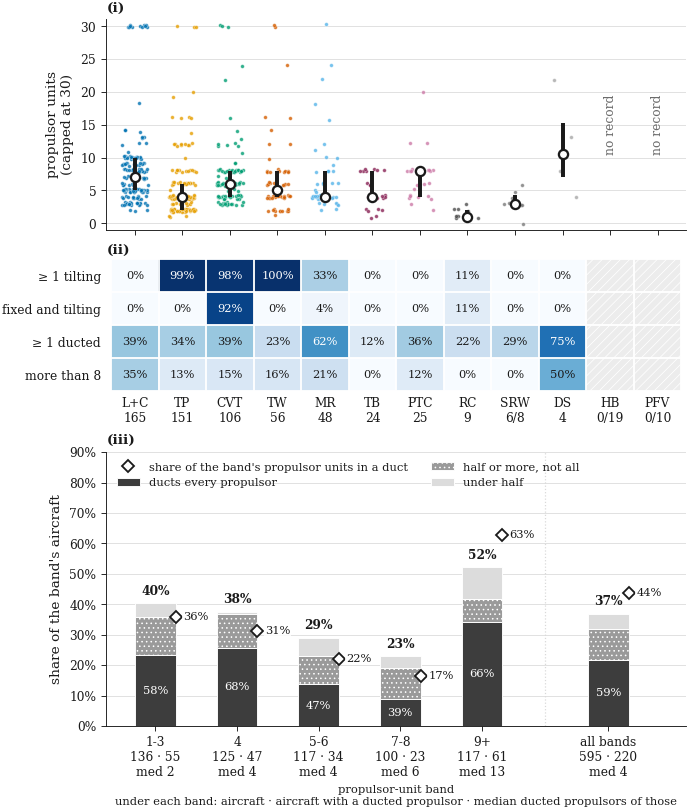

In [8]:
fig = plt.figure(figsize=(W, 7.4), constrained_layout=True)
gs = fig.add_gridspec(3, 1, height_ratios=[2.0, 1.25, 2.6])
ax1, ax2, ax3 = (fig.add_subplot(g) for g in gs)
plots.unit_strips(ax1, codes, units_by_class, cap=30, seed=SEED)
ax1.set_xlim(-0.6, len(codes) - 0.4); ax1.set_xticks(range(len(codes)), [])
ax1.set_ylabel('propulsor units\n(capped at 30)'); style.mark(ax1, '(i)')
ROWS = {'at least one tilting propulsor': '≥ 1 tilting', 'both fixed and tilting propulsors': 'fixed and tilting',
        'a ducted propulsor': '≥ 1 ducted', 'more than 8 propulsors': 'more than 8'}
plots.feature_heat(ax2, feat.rename(index=ROWS))
plots.class_ticks(ax2, codes, [f"{n}" if r == n else f"{r}/{n}" for r, n in zip(read, total)])
style.mark(ax2, '(ii)')
plots.duct_bands(ax3, dcount, dcond)
ax3.set_ylabel("share of the band's aircraft")
ax3.set_xlabel('propulsor-unit band\nunder each band: aircraft · aircraft with a ducted propulsor · median ducted propulsors of those', fontsize=7.5)
ax3.legend(loc='upper left', ncol=2, fontsize=7.5); style.mark(ax3, '(iii)')
plt.show()

In [9]:
fig6_units = pd.concat([pd.DataFrame({'class': style.cls(c).name, 'propulsor units': u}) for c, u in zip(codes, units_by_class)], ignore_index=True)
save.table(fig6_units, cfg, 'q2', 'fig_06_i_units_per_aircraft', caption='Figure 6 (i), the propulsor units of every aircraft by class.', source='human labelling')
save.table(feat.round(3).reset_index().rename(columns={'index': 'feature'}), cfg, 'q2', 'fig_06_ii_arrangement_share',
           caption='Figure 6 (ii), share of each class with each arrangement feature.', source='human labelling')
save.figure(fig, cfg, 'q2', 'fig_06_propulsion_compact', data=dcount.merge(dcond, on='propulsive units'),
            caption='three graphs: (i) propulsor units per class, (ii) how each class arranges them, (iii) ducting per propulsor-unit band.',
            source='human labelling (the propulsion record of each place: propulsor units, tilt and duct per propulsor type)',
            unit=f"unique aircraft (627); units read on the {len(unit)} with a propulsion record ({int(dcount['aircraft'].iloc[-1])} with a unit count above zero in (iii)); a column of (ii) under HB and PFV is empty because the codebook gives them no propulsor card",
            read='(i) Dot: one aircraft (jittered sideways, units above 30 drawn at 30); bar: the middle half of the class; ring: the median, which a few aircraft with very many propulsor units do not pull. (ii) Cell: the share of the class with the feature (tilting: at least one propulsor tilts, on its mount, on a tilting wing, on a tilting boom group or on a tilting tail; fixed and tilting: both kinds on one aircraft; ducted: at least one ducted propulsor; more than 8 propulsors); under the class: aircraft (read/total where a propulsion record is missing). (iii) Bar height: share of the band\'s aircraft with at least one ducted propulsor, split into the aircraft that duct every propulsor (dark, with its share of the ducting aircraft printed in white), half or more but not all, and under half; diamond: the share of all the band\'s propulsor units that sit in a duct; under each band: aircraft, aircraft that duct, median ducted propulsors of those.',
            panels={'(i)': 'propulsor units per class', '(ii)': 'arrangement features per class', '(iii)': 'ducting per propulsor-unit band'})
plt.close(fig)

### 2.1 numbers

In [10]:
t6i = t6.set_index('name')
dci = dcount.set_index('propulsive units')
N1 = {
    'units_n': str(len(unit)), 'units_median': f"{unit.median():g}",
    'tk_emptype': pct(t6i.loc['tail type', 'top_share']), 'tk_units_top': pct(t6i.loc[frames.D3_UNITS_ROW, 'top_share']),
    'sm_d3_wings_top': pct(t6i.loc['number of wings', 'top_share']), 'sm_d3_drop_share': pct(cut),
    'sm_duct13_med': f"{dci.loc['1-3', 'median ducted units (ducted aircraft)']:.0f}",
    'sm_duct9_med': f"{dci.loc['9+', 'median ducted units (ducted aircraft)']:.1f}",
    'sm_duct9_units': pct(dci.loc['9+', 'share of units ducted']),
}
numbers_check(N1)

,name,notebook,document,match
0,units_n,596,596,yes
1,units_median,5,5,yes
2,tk_emptype,29 %,29 %,yes
3,tk_units_top,23 %,23 %,yes
4,sm_d3_wings_top,57 %,57 %,yes
5,sm_d3_drop_share,88 %,88 %,yes
6,sm_duct13_med,2,2,yes
7,sm_duct9_med,13.0,13.0,yes
8,sm_duct9_units,63 %,63 %,yes


## 2.2 — How are designs grouped into archetypes, and in which archetype set is the space read?

#### Method

**What an archetype is.** A design described by a few chosen labels: write each aircraft as its answers on those labels, and two aircraft share an archetype when every answer is the same. The set of labels chosen is the **archetype set**; each aircraft has exactly one archetype in each archetype set.


**How it is written.** An archetype set is named by letters for the labels it combines (**C** class, **W** wings, **T** tilt, **U** propulsor-unit band), and an archetype is written in words, one label after another:

- *Lift + Cruise · one wing · no tilting propulsor*, archetype set **C·W·T**: the class is Lift + Cruise, the aircraft has one wing, and none of its propulsors tilts.
- *Tilt Propulsor · 1-3 propulsor units*, archetype set **C·U**: the class is Tilt Propulsor and the aircraft has one to three propulsor units.

**Why these archetype sets.** 9 archetype sets were built, combining the class with wings, booms, tail, tilt and the propulsor-unit band; the finer ones run to 348 archetypes, most holding one or two aircraft, where no share can be read. Four screens, fixed before the archetype sets were compared, keep an archetype set only if it adds to the class (at least twice as many archetypes as classes), leaves few aircraft alone (at most 5 %), puts most aircraft in archetypes of 5 or more (at least 90 %) and has at least 3 archetypes of 5 % or more. 3 archetype sets pass: C·W·T, C·U and class + wings + booms, which is set aside because booms carry propulsors but do not decide how the aircraft lifts or cruises. The class alone fails only the first screen, because it *is* the class, and is kept as the reference.

| archetype set | combines | why it is read |
|---|---|---|
| **C** (class) | the architecture class | the reference: how the aircraft passes from hover to cruise |
| **C·W·T** (class + wings + tilt) | class · number of wings · whether any propulsor tilts | the two further decisions that change how the aircraft flies; the archetype set the dominant-design test was written at |
| **C·U** (class + propulsor units) | class · propulsor-unit band | the decision distributed electric propulsion moves: a four-propulsor Lift + Cruise against a twelve-propulsor one |
| **F** (Lift + Cruise + CVT* family) | the class, with the family below as one archetype | one design across two classes; chosen after the first readings of the data |

**The Lift + Cruise + CVT\* family (F)** holds every Lift + Cruise aircraft plus every **CVT\*** aircraft (a CVT whose tilting part is a propulsor set on a fixed wing): 246 aircraft; every other aircraft keeps its class.

- *Why these two:* Figure 13 (chapter 3.3) shows the same closeness in each class's own leading layout. Lift + Cruise keeps its lift propulsors on booms as its leading layout, and CVT*'s leading layout becomes tilting propulsors with the fixed ones on booms. Both are a fixed wing that never tilts, carrying propulsors spread over the airframe, and they differ only in whether cruise thrust comes from dedicated propellers (Lift + Cruise or some CVT propellers) or from tilting some of the propulsors (this CVT). The criterion is morphological similarity with a slight difference in function.
- *Chosen after the first readings of the data:* the family was defined after the class and archetype readings had been seen; no result on it is a pre-registered test, and this is stated wherever it appears.

**What is measured: Table 7.** Per archetype set: the archetypes, its **singletons** (archetypes held by one aircraft only), ¹D (box below) and the largest archetype with its share. *Unit:* the unique aircraft, each written once per archetype set, over the **whole corpus and all years** (no time windows), because the question is what the archetype set does to the count; ¹D is therefore not rarefied. Shares per priority window are chapter 3. Source: human labelling.


##### ¹D, ²D and Q: how many designs are in play, and how alike the aircraft are

**Why not simply count archetypes.** A plain count treats a **singleton** (an archetype held by one aircraft only) exactly like an archetype held by forty aircraft, so ten archetypes could mean ten roughly equal designs, or it could mean one archetype with forty aircraft and nine singletons: very different spreads, the same count of ten. The **effective number** corrects for this: it is the count of equally sized archetypes that would spread the same aircraft the same way, so the one-big-archetype-plus-singletons case gets a low effective number even though its plain count is high.

**How the two are computed.** Write pᵢ for the share of the window's aircraft in archetype i (its aircraft divided by all the aircraft of the window).

- **¹D = exp(H), with H = −Σ pᵢ ln pᵢ** (the Shannon entropy). In words: H measures how hard it is to guess the archetype of an aircraft drawn at random; exp turns that back into a number of archetypes. Every archetype counts in proportion to its share.
- **²D = 1 / Σ pᵢ²** (the inverse Simpson index). In words: Σ pᵢ² is the chance that two aircraft drawn at random share an archetype; ²D is one over that chance. Squaring the shares makes the large archetypes weigh more and the rare ones almost vanish.
- Always ²D ≤ ¹D ≤ the count of archetypes; all three are equal only when every archetype is equally common. These are Hill numbers of order 1 and 2 (Hill, 1973), read here as effective numbers of archetypes following Jost's (2006) account of diversity as numbers equivalents.

**Worked example: invented round numbers, for illustration only, not from this corpus.** A window holds four archetypes.

| shares of the four archetypes | H = −Σ pᵢ ln pᵢ | ¹D = exp(H) | Σ pᵢ² | ²D = 1 / Σ pᵢ² |
|---|---|---|---|---|
| 25 / 25 / 25 / 25 % | 1.39 | 4.0 | 0.25 | 4.0 |
| 70 / 10 / 10 / 10 % | 0.94 | 2.56 | 0.49 + 3 × 0.01 = 0.52 | 1.92 |

- Evenly split, four archetypes behave like four.
- With one archetype at 70 %, the same four behave like about two and a half (¹D), or, counting only the ones that carry weight, like about two (²D).
- **The difference between the two:** ¹D describes how spread the whole field is, tail included; ²D describes how many *large* designs there are. A dominant design is a question about the large ones, so ²D is the number the dominant-design test reads (condition 2); ¹D describes the archetype sets and the windows.

**The Gower distance and Rao's Q: how alike the aircraft are** (condition 3 of the dominant-design test, 3.2). ¹D and ²D count designs by name; Q measures how different the aircraft themselves are, field by field.

- **Gower distance between two aircraft i and j: d(i,j) = Σ_f w_f δ_f d_f / Σ_f w_f δ_f** (Gower, 1971). In words: the weighted mean, over the design fields f, of the per-field difference d_f. On a category field d_f is 0 for the same answer and 1 for a different one; on a count it is |x_i − x_j| / range, the gap as a fraction of the widest gap in the corpus. δ_f is 0 when either aircraft leaves the field blank, so a blank is skipped, never counted as a difference. d runs from 0 (the same on every field) to 1 (different on every field). The weights w_f: in the main weighting each of the six subsystems carries the same total weight, shared among its fields; in the check every field carries the same weight.
- **Rao's quadratic entropy: Q = (1/N²) Σ_i Σ_j d(i,j)** over the N aircraft of a window (Rao, 1982). In words: the average distance over all pairs of the window's aircraft, which is the expected distance between two aircraft drawn at random from it. Q falls when the aircraft of a window resemble each other.

**Rarefaction: comparing windows of different sizes.** A window with more aircraft happens to include more rare archetypes simply by holding more aircraft, so it could look more diverse than an earlier, smaller window even when both are drawn from the same mix of designs. Rarefaction removes this: every window is cut down to the same number of aircraft, 40, at random, and ¹D and ²D are computed on that cut-down sample; the draw is repeated many times and the results averaged, so a bigger window cannot look more varied just by being bigger.

**The permutation band: what chance alone gives.** A ²D of its own cannot say whether it is low. The band is built from the same aircraft:

1. every aircraft keeps its archetype, and every window keeps its number of aircraft;
2. which aircraft sits in which window is shuffled at random, so the priority year no longer means anything;
3. ²D is recomputed for every window of the shuffled corpus;
4. this is repeated 200 times. The seed (42) is only the random generator's starting position, fixed so a rerun gives back the identical numbers; the value itself is an arbitrary convention. The band is what remains after the lowest and highest 2.5 % of the 200 results are cut, so it is the region chance alone produces, and a real value outside it is one chance would almost never produce (statistics box of chapter 1).

- A real value **inside** the band is what any random split of the corpus into windows of these sizes would show: nothing the years explain.
- A real value **below** the band means the window holds fewer designs in play than chance gives it: that is condition 2 of the dominant-design test (chapter 3).
- Condition 3 of the same test (chapter 3) builds its band by the same shuffle, on a different statistic.

### The nine archetype sets and the four screens

Nine archetype sets can be formed from the codebook (the class with wings, booms, tail, tilt and the propulsor-unit band). For each: the archetypes, the aircraft alone in theirs, ¹D (`lib.diversity.effective_number`), ²D (`lib.concentration.inverse_hhi`), the largest archetype and the archetypes of five or more (`frames.archetype_levels_table`), over the whole corpus and all years. The four screens (lines from `analysis.archetype_screens`) are applied in `frames.archetype_screens`; both tables are checked against the document.

In [11]:
levels = frames.archetype_levels_table(ds, v, cfg)
LV_COLS = ['level', 'largest archetype', 'aircraft', 'left out', 'archetypes', 'singletons', 'singleton share', 'effective number ¹D',
           'effective number ²D', 'largest share', 'top three share', 'archetypes of five or more', 'share in archetypes of five or more',
           'archetypes holding 5 % or more']
verify(levels, 'la_archetype_levels', key=['level'], columns=LV_COLS)
screens = frames.archetype_screens(levels, cfg)
verify(screens, 'la_archetype_choice', key=['level'], columns=['level', 'screens passed'])
sets9 = levels.assign(set=levels['level'].map(lambda s: frames.SET_CODES[s][0]))[['set', 'archetypes', 'singletons', 'effective number ¹D', 'effective number ²D', 'archetypes of five or more']]
sets9.merge(screens[['level', 'screens passed']].assign(set=screens['level'].map(lambda s: frames.SET_CODES[s][0]))[['set', 'screens passed']], on='set')

,la_archetype_levels
table,la_archetype_levels
rows (notebook | document),9 | 9
cells compared,117
matched,117
expected differences,0
differences,0
status,match


,la_archetype_choice
table,la_archetype_choice
rows (notebook | document),9 | 9
cells compared,9
matched,9
expected differences,0
differences,0
status,match


,set,archetypes,singletons,effective number ¹D,effective number ²D,archetypes of five or more,screens passed
0,C,12,0,7.3,5.7,11,3 of 4
1,C·U,43,3,29.4,22.6,33,4 of 4
2,C·W·B,57,17,28.0,20.4,25,4 of 4
3,C·W·B·U,152,63,90.8,58.7,48,1 of 4
4,C·W·B#,76,23,39.0,26.4,32,3 of 4
5,C·W·T,39,10,16.4,11.3,20,4 of 4
6,C·W·T·U,109,39,60.6,40.5,42,1 of 4
7,C·W·B·E,191,83,122.6,85.8,41,1 of 4
8,C·W·B·E·U,348,225,265.4,183.5,14,1 of 4


### ¹D and ²D on the worked example

The worked example of the statistics box (invented round numbers), computed by the same two lib functions: four archetypes of 25 / 25 / 25 / 25 aircraft, and of 70 / 10 / 10 / 10 aircraft.

In [12]:
rows = []
for sizes in ([25, 25, 25, 25], [70, 10, 10, 10]):
    labels = pd.Series(np.repeat(list('abcd'), sizes))
    d1, d2 = diversity.effective_number(labels), concentration.inverse_hhi(labels.value_counts())
    rows.append({'shares': ' / '.join(str(s) for s in sizes) + ' %', 'H = −Σ pᵢ ln pᵢ': f"{np.log(d1):.2f}", '¹D = exp(H)': f"{d1:.2f}".rstrip('0').rstrip('.') if d1 == 4 else f"{d1:.2f}",
                 'Σ pᵢ²': f"{1 / d2:.2f}", '²D = 1 / Σ pᵢ²': f"{d2:.2f}"})
worked = pd.DataFrame(rows)
DOC_WORKED = [['25 / 25 / 25 / 25 %', '1.39', '4', '0.25', '4.00'], ['70 / 10 / 10 / 10 %', '0.94', '2.56', '0.52', '1.92']]     # as the Method box prints them (4.0 = 4.00)
assert worked.values.tolist() == DOC_WORKED, worked
worked

,shares,H = −Σ pᵢ ln pᵢ,¹D = exp(H),Σ pᵢ²,²D = 1 / Σ pᵢ²
0,25 / 25 / 25 / 25 %,1.39,4,0.25,4.00
1,70 / 10 / 10 / 10 %,0.94,2.56,0.52,1.92


### Table 7 — the four archetype sets the document reads

C, C·W·T, C·U and the Lift + Cruise + CVT* family F (every Lift + Cruise aircraft plus every CVT whose tilting part is a propulsor set on a fixed wing: `frames.family_flags`, `frames.family_mask`). Over the whole corpus, all years: ¹D is therefore not rarefied. The comparison maps the display names (Tilt Propulsor, propulsor units) to the document's.

In [13]:
brief = frames.archetype_levels_brief(ds, v, levels)
BRIEF_COLS = ['level id', 'aircraft', 'archetypes', 'aircraft alone in their archetype', 'effective number ¹D', 'largest archetype', 'its share',
              'archetypes of five or more']
verify(brief, 'la_archetype_levels_brief', key=['level id'], columns=BRIEF_COLS,
       rename={'Tilt Propulsor · 1-3 propulsor units': 'Tilt Rotor · 1-3 units'})
SET_LABEL = {'A0': 'C (class)', 'A1t': 'C·W·T (class + wings + tilt)', 'A0c': 'C·U (class + propulsor units)', 'family_b': 'F (Lift + Cruise + CVT* family)'}
tab7 = pd.DataFrame({'archetype set': brief['level id'].map(SET_LABEL), 'archetypes': brief['archetypes'], 'singletons': brief['aircraft alone in their archetype'],
                     '¹D': brief['effective number ¹D'], 'largest archetype': brief['largest archetype'], 'its share': brief['its share']})
save.table(tab7, cfg, 'q2', 'tab_7_archetype_sets', caption='The four archetype sets this document reads (what each combines is in the Method): how many archetypes it yields, how many are singletons, the effective number of archetypes ¹D and the largest archetype with its share over the whole corpus, all years together. F, the Lift + Cruise + CVT* family, was chosen after the first readings of the data.', source='human labelling')
tab7

,la_archetype_levels_brief
table,la_archetype_levels_brief
rows (notebook | document),4 | 4
cells compared,28
matched,28
expected differences,0
differences,0
status,match


,archetype set,archetypes,singletons,¹D,largest archetype,its share
0,C (class),12,0,7.3,Lift + Cruise,0.264
1,C·W·T (class + wings + tilt),39,10,16.4,Lift + Cruise · one wing · no tilting propulsor,0.167
2,C·U (class + propulsor units),43,3,29.4,Tilt Propulsor · 1-3 propulsor units,0.098
3,F (Lift + Cruise + CVT* family),12,0,6.2,Lift + Cruise + CVT* family,0.394


### 2.2 numbers

In [14]:
flags = frames.family_flags(ds, v)
fam_n = int(frames.family_mask(flags[flags['topType'].notna()]).sum())
winn = v['window'].value_counts()
active = int(winn['2016-19'] + winn['2020-23'])
sc = cfg.analysis['archetype_screens']
L = brief.set_index('level id')
N2 = {
    'sm_arch_levels': str(len(levels)), 'sm_arch_max': str(int(levels['archetypes'].max())),
    'sm_arch_pass': str(int((screens['screens passed'] == '4 of 4').sum())),
    'sm_screen_big': str(sc['big_archetype_aircraft']), 'sm_screen_frag': pct(sc['max_singleton_share']), 'sm_screen_pop': pct(sc['min_share_in_big']),
    'sm_screen_readable': str(sc['min_big_share_archetypes']), 'sm_screen_share': pct(sc['big_archetype_share']),
    'sm_fam_b_n': str(fam_n),
    'sm_lv_c_arch': str(L.loc['A0', 'archetypes']), 'sm_lv_c_eff': f"{L.loc['A0', 'effective number ¹D']:.1f}",
    'sm_lv_cu_arch': str(L.loc['A0c', 'archetypes']), 'sm_lv_cu_big': str(L.loc['A0c', 'archetypes of five or more']),
    'sm_lv_cwt_arch': str(L.loc['A1t', 'archetypes']), 'sm_lv_cwt_big': str(L.loc['A1t', 'archetypes of five or more']),
    'sm_lv_f_share': pct(L.loc['family_b', 'its share']),
}
numbers_check(N2)

,name,notebook,document,match
0,sm_arch_levels,9,9,yes
1,sm_arch_max,348,348,yes
2,sm_arch_pass,3,3,yes
3,sm_screen_big,5,5,yes
4,sm_screen_frag,5 %,5 %,yes
5,sm_screen_pop,90 %,90 %,yes
6,sm_screen_readable,3,3,yes
7,sm_screen_share,5 %,5 %,yes
8,sm_fam_b_n,246,246,yes
9,sm_lv_c_arch,12,12,yes


## 2.3 — Where do designs concentrate, and is the design space still open?

#### Method

**The archetype read here is C·U**, the class with its propulsor-unit band: it splits every class by the field that varies most (2.1), and yields the most archetypes large enough to read: 33 of five aircraft or more, against 20 at C·W·T, whose tilt answer inside the large classes is fixed by the class. The figures write an archetype short (*L+C 9+* = Lift + Cruise with nine propulsor units or more; class abbreviations in the legend of Figure 8).


- **Who files each large archetype: Figure 7.** **Distinct filers per aircraft** = the archetype's filers divided by its aircraft; a filer is a firm, and an individual inventor's patent is its own filer. 1.00 means every aircraft has a different filer; a low value is the trace of one firm's line of variants. Read first, because it says whether a large archetype on the map is many designers' choice or one firm filing again. *Unit:* the C·U archetype with 20 aircraft or more (11); on fewer, one filer moves the ratio by a large step. Sources: human labelling, PatSeer (applicant).
- **Where the recent aircraft concentrate: Figure 8.** *Unit:* the C·U archetype with five aircraft or more (33).
  - *(i)* Left to right: the archetype's share of the aircraft with a priority year from 2016 to 2023, from the take-off of filing (chapter 1) to the last year whose publication lag has run; these two windows hold 450 aircraft (72 %) against 63 and 58 in the two before, so the axis says where today's designers are. Bottom to top: distinct filers per aircraft. ▲ first seen in 2016 or later, ▼ not seen after 2019, ● throughout. The **crowded core** (solid ring) is the largest archetypes that together hold half of the 2020-23 aircraft, the columns left of that window's orange bar in (ii); the **empty rim** (dashed) is at or below the median share, the vertical grey line. Both are set by rule, not by eye.
  - *(ii)* Each archetype's aircraft per window, largest first; the orange bar marks the column by which half the window's aircraft are reached. As the order is the total over all windows, the count is repeated with each window in its own order. Sources: human labelling, PatSeer (applicant; priority date).
- **Whether the space is still opening: Figure 9.** *Why it matters:* a space that no longer produces new kinds of design can only converge among those it holds. Two lines are drawn at each of C, C·U and C·W·T: the solid line adds the aircraft one at a time in priority order and counts the distinct archetypes seen so far (shaded: the spread over tie orderings inside a year); the dotted line does the same count with the aircraft shuffled into a fully random order, the reference for what accumulation alone would give. The grey band marks the last 100 aircraft filed, where the two lines are read off: the new archetypes date order actually brought in that span, against what a random 100 aircraft would have brought by chance. A Chao1 estimate of what is still unseen, from the archetypes seen once and twice, a floor and never a forecast, completes the reading. *Unit:* the unique aircraft with a priority year up to 2023, whose publication lag has run. Sources: human labelling, PatSeer (priority date).

### The C·U archetypes: zones and filers

`frames.zones` gives, for every C·U archetype of five aircraft or more (`analysis.zone_min_aircraft`), its aircraft, distinct filers (a firm, or an individual inventor's patent as its own filer), the share of the 2016-23 aircraft, the zone (new since 2016 / fading / persistent) and the aircraft per window. `frames.zone_core` marks the crowded core by rule, `frames.archetype_filer_split` says who the largest filer of each archetype of 20 aircraft or more is. Both tables are checked against the document (the class column prints the codes of the data; the display names are in the figures).

In [15]:
zones = frames.zones(v, WIN_NAMES, cfg.analysis['zone_min_aircraft'])
verify(zones, 'la_zones', key=['archetype'], columns=[c for c in zones.columns if c != 'class'])
split = frames.archetype_filer_split(v, cfg.analysis['filer_panel_min_aircraft'])
verify(split, 'la_archetype_filer_split', key=['archetype'])
zz = zones[zones['filers 2016-23'] > 0]
core = zz[frames.zone_core(zones).reindex(zz.index).fillna(False).astype(bool)]
rim = zz[zz['share 2016-23'] <= zz['share 2016-23'].median()]
half = {w: frames.half_column(zones[w]) for w in ('2016-19', '2020-23')}
display(zones[['archetype', 'aircraft', 'filers', 'filers per aircraft', 'share 2016-23', 'zone'] + WIN_NAMES])
display(split)

,la_zones
table,la_zones
rows (notebook | document),33 | 33
cells compared,495
matched,495
expected differences,0
differences,0
status,match


,la_archetype_filer_split
table,la_archetype_filer_split
rows (notebook | document),11 | 11
cells compared,66
matched,66
expected differences,0
differences,0
status,match


,archetype,aircraft,filers,filers per aircraft,share 2016-23,zone,<= 2011,2012-15,2016-19,2020-23,2024-26 (partial)
0,TR · 1-3,61,38,0.62,0.076,persistent,13,14,21,13,0
1,SLC · 9+,57,40,0.70,0.092,persistent,9,2,16,25,5
2,SLC · 5-6,42,35,0.83,0.065,persistent,4,4,11,18,5
3,TR · 4,38,33,0.87,0.069,persistent,3,3,16,15,1
4,SLC · 7-8,32,24,0.75,0.056,persistent,2,2,8,17,3
5,CVT · 5-6,29,15,0.52,0.054,persistent,1,2,6,18,2
6,CVT · 7-8,24,15,0.62,0.042,persistent,0,1,7,12,4
7,CVT · 4,22,22,1.00,0.033,persistent,1,2,8,7,4
8,SLC · 1-3,21,19,0.90,0.033,persistent,2,1,7,8,3
9,TR · 5-6,20,16,0.80,0.020,persistent,3,3,4,5,5


,archetype,aircraft,filers,filers per aircraft,largest filer,its aircraft,filers holding one aircraft
0,CVT · 5-6,29,15,0.52,Bell / Textron,13,12
1,CVT · 7-8,24,15,0.62,Leonardo,4,9
2,TR · 1-3,61,38,0.62,Bell / Textron,15,31
3,SLC · 9+,57,40,0.70,Honda,6,30
4,SLC · 7-8,32,24,0.75,Airbus,4,18
5,TR · 5-6,20,16,0.80,Bell / Textron,4,14
6,SLC · 5-6,42,35,0.83,Airbus,3,30
7,TR · 9+,20,17,0.85,Mitsubishi,2,14
8,TR · 4,38,33,0.87,Bell / Textron,6,32
9,SLC · 1-3,21,19,0.90,Airbus,2,17


### Figure 7 — distinct filers per aircraft for the largest C·U archetypes

One bar per C·U archetype with 20 aircraft or more (colour and hatch of its class); Combined Vectored Thrust with 5-6 propulsor units and CVT · 4 beside it are outlined.

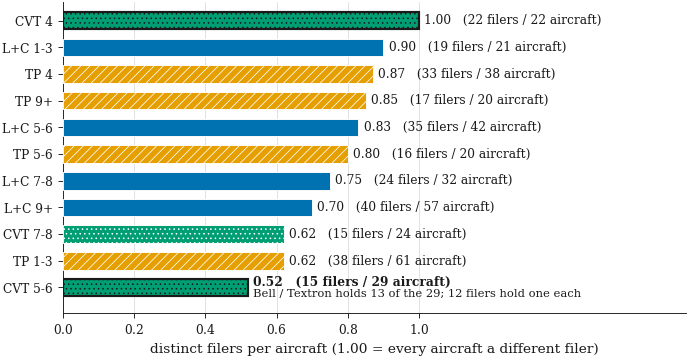

In [16]:
f7 = split.sort_values('filers per aircraft', ascending=False).merge(zones[['archetype', 'code']], on='archetype')
f7['label'] = f7['archetype'].map(short)
FOCUS, NEIGH = 'CVT · 5-6', 'CVT · 4'
top = split.set_index('archetype').loc[FOCUS]
fig, ax = plt.subplots(figsize=(W, 3.3), constrained_layout=True)
plots.filer_bars(ax, f7, [FOCUS, NEIGH], FOCUS, f"{top['largest filer']} holds {int(top['its aircraft'])} of the {int(top['aircraft'])}; {int(top['filers holding one aircraft'])} filers hold one each")
ax.set_xlim(0, 1.75); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel('distinct filers per aircraft (1.00 = every aircraft a different filer)')
plt.show()
save.figure(fig, cfg, 'q2', 'fig_07_archetype_filers', data=f7.drop(columns='label'),
            caption='distinct filers per aircraft for the largest C·U archetypes (class + propulsor-unit band); Combined Vectored Thrust with 5-6 propulsor units (CVT · 5-6) is marked, and CVT · 4 beside it.',
            source='human labelling (class, propulsor units) · PatSeer (applicant, read as filer)',
            unit=f"C·U archetypes with {cfg.analysis['filer_panel_min_aircraft']} or more unique aircraft ({len(f7)}); on fewer, one filer moves the ratio by a large step",
            read="Bar: the archetype's distinct filers divided by its aircraft (a filer is a firm; an individual inventor's patent is its own filer). 1.00 means every aircraft has a different filer; a low value is the trace of one firm's line of variants. After the bar: the ratio and (filers / aircraft). Outlined: CVT with 5-6 propulsor units, the lowest, with the split of its filers, and CVT with 4 propulsor units beside it.")
plt.close(fig)

### Figure 8 — where the recent aircraft concentrate

(i) Each C·U archetype of five aircraft or more by its share of the 2016-23 aircraft (the two windows whose publication lag has run: 450 aircraft) and its distinct filers per aircraft; bubble area is the archetype's aircraft; ▲ first seen in 2016-19 or later, ▼ not seen after 2016-19, ● throughout. The crowded core (solid ring) is the largest archetypes that together hold half of the 2020-23 aircraft (`frames.zone_core`); the empty rim (dashed) is at or below the median share (the vertical grey line). (ii) Aircraft per window for each archetype, largest first; the orange bar marks the column by which half the window's aircraft are reached. An archetype is labelled in (i) when it holds 12 aircraft or more, 3 % of the 2016-23 aircraft or more, or has fewer than 0.75 filers per aircraft; every archetype is named in (ii).

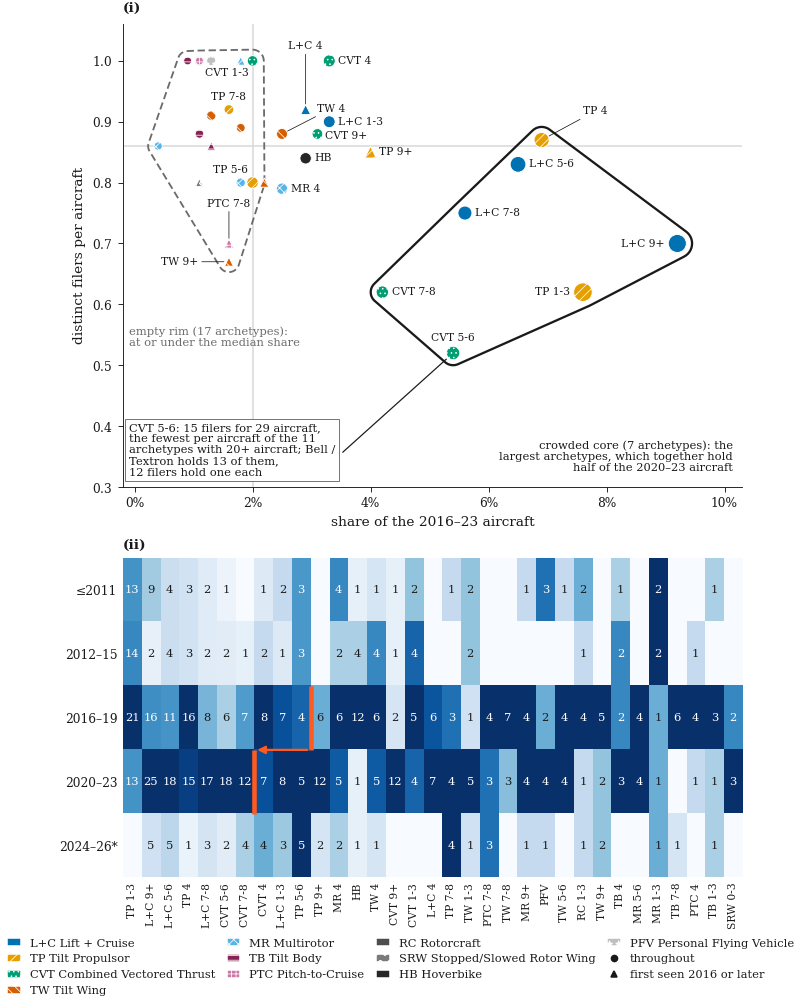

In [17]:
WLAB = {'<= 2011': '≤2011', '2012-15': '2012–15', '2016-19': '2016–19', '2020-23': '2020–23', '2024-26 (partial)': '2024–26*'}
mx, my = zz['share 2016-23'].median(), zz['filers per aircraft'].median()
bubble = lambda n: 14 + 2.2 * np.asarray(n, dtype=float)                      # marker area, pt²
radius = lambda d: np.sqrt(bubble(d['aircraft']) / np.pi)                      # marker radius, pt
fig = plt.figure(figsize=(W, 9.2), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[1.45, 1])
ax = fig.add_subplot(gs[0]); ax2 = fig.add_subplot(gs[1])
for _, r in zz.iterrows():
    s = style.cls(r['code'])
    ax.scatter(r['share 2016-23'], r['filers per aircraft'], s=bubble(r['aircraft']), color=s.color, hatch=s.hatch, edgecolor='white',
               linewidth=0.6, marker={'new': '^', 'fading': 'v'}.get(r['zone'], 'o'), zorder=3)
ax.set_xlim(-0.002, zz['share 2016-23'].max() * 1.12); ax.set_ylim(0.3, 1.06)
ax.axvline(mx, color=style.GRID, linewidth=1, zorder=0); ax.axhline(my, color=style.GRID, linewidth=1, zorder=0)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set_xlabel('share of the 2016–23 aircraft'); ax.set_ylabel('distinct filers per aircraft'); style.mark(ax, '(i)')
# (ii)
mat = zones.set_index('archetype')[WIN_NAMES].astype(float).T
m2 = mat.rename(index=WLAB); m2.columns = [short(a) for a in m2.columns]
plots.window_heat(ax2, m2, {WLAB[w]: j for w, j in half.items()})
ax2.tick_params(axis='x', labelsize=7); style.mark(ax2, '(ii)')
# the key, then the layout is final and the labels can be placed
codes8 = [c for c in style.CLASS_ORDER if c in set(zz['code'])]
handles = [Patch(facecolor=style.cls(c).color, hatch=style.cls(c).hatch, edgecolor='white', label=f"{style.cls(c).short} {style.cls(c).name}") for c in codes8]
handles += [Line2D([], [], marker='o', color=style.INK, linestyle='none', label='throughout'),
            Line2D([], [], marker='^', color=style.INK, linestyle='none', label='first seen 2016 or later')]
fig.legend(handles=handles, loc='outside lower center', ncol=4, fontsize=7.5, handlelength=1.2, columnspacing=1.0)
fig.canvas.draw()
ring_core = plots.hull_ring(ax, core['share 2016-23'], core['filers per aircraft'], radius(core), pad_pt=3, linewidth=1.5)
ring_rim = plots.hull_ring(ax, rim['share 2016-23'], rim['filers per aircraft'], radius(rim), pad_pt=3.5, linewidth=1.2, linestyle=(0, (4, 2)), edgecolor=style.MUTED)
def along(h, pad=3):
    pts = [a + (b - a) * t for a, b in zip(h, np.roll(h, -1, axis=0)) for t in np.linspace(0, 1, 12)]
    return [Bbox([[x - pad, y - pad], [x + pad, y + pad]]) for x, y in pts]
t_core = ax.text(0.985, 0.03, f"crowded core ({len(core)} archetypes): the\nlargest archetypes, which together hold\nhalf of the 2020–23 aircraft", transform=ax.transAxes,
                 ha='right', va='bottom', fontsize=7.5, linespacing=1.15)
t_rim = ax.text(0.01, 0.3, f"empty rim ({len(rim)} archetypes):\nat or under the median share", transform=ax.transAxes, ha='left', va='bottom',
                fontsize=7.5, linespacing=1.15, color=style.MUTED)
cvt = zz[zz['archetype'] == FOCUS].iloc[0]
callout = (f"{short(FOCUS)}: {int(cvt['filers'])} filers for {int(cvt['aircraft'])} aircraft,\nthe fewest per aircraft of the {len(split)}\n"
           f"archetypes with {cfg.analysis['filer_panel_min_aircraft']}+ aircraft; {top['largest filer'].split(' / ')[0]} /\n{top['largest filer'].split(' / ')[-1]} holds {int(top['its aircraft'])} of them,\n"
           f"{int(top['filers holding one aircraft'])} filers hold one each")
t_cv = ax.text(0.01, 0.02, callout, transform=ax.transAxes, ha='left', va='bottom', fontsize=7.5, linespacing=1.15, bbox=dict(fc='white', ec=style.MUTED, lw=0.6, pad=2.5))
ax.annotate('', xy=(cvt['share 2016-23'], cvt['filers per aircraft']), xytext=(0.355, 0.075), textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-', lw=0.8, color=style.INK, shrinkA=0, shrinkB=float(radius(cvt.to_frame().T)[0]) + 1))
fig.canvas.draw()
rend = fig.canvas.get_renderer()
obstacles = along(ring_core) + along(ring_rim) + [t.get_window_extent(rend).expanded(1.03, 1.1) for t in (t_core, t_rim, t_cv)]
lab = zz[(zz['aircraft'] >= 12) | (zz['share 2016-23'] >= 0.03) | (zz['filers per aircraft'] < 0.75)]
failed = plots.place_labels(ax, lab['share 2016-23'].to_numpy(), lab['filers per aircraft'].to_numpy(), [short(a) for a in lab['archetype']], radius(lab),
                            obstacles=obstacles, fontsize=7, extra_avoid=list(zip(zz['share 2016-23'], zz['filers per aircraft'], radius(zz))))
assert not failed, failed
plt.show()

In [18]:
save.figure(fig, cfg, 'q2', 'fig_08_zones', data=zones,
            caption='the C·U archetypes with five aircraft or more: where the recent aircraft concentrate and how many filers stand behind them, with the crowded core ringed (the largest archetypes, which together hold half of the 2020-23 aircraft), then the aircraft of each archetype per priority window. (i) the crowded core and the empty rim; (ii) aircraft per window for each archetype.',
            source='human labelling (class, propulsor units) · PatSeer (applicant, priority date)',
            unit=f"C·U archetypes with {cfg.analysis['zone_min_aircraft']} or more unique aircraft ({len(zones)}); (i) the {len(zz)} that have an aircraft in 2016-23, (ii) unique aircraft ({int(mat.to_numpy().sum())}) in the same {mat.shape[1]} archetypes per priority window; * the window 2024-26 is partial",
            read=f"(i) Right: the archetype holds a large share of the 2016-23 aircraft; up: it is filed by many different filers per aircraft (an open field), down: by few filers with many aircraft each. Bubble area: the archetype's aircraft; colour and hatch: its class; shape: first seen in 2016-19 or later (triangle up), not seen after 2016-19 (triangle down), throughout (circle). Solid ring: the crowded core ({len(core)} archetypes); dashed ring: the empty rim ({len(rim)} archetypes). Not every archetype is labelled in (i): those with fewer than 12 aircraft, under 3 % of the 2016-23 aircraft and 0.75 filers per aircraft or more are named in (ii). (ii) Columns: the same archetypes, largest first; cell: its aircraft in the window, shaded by its own busiest window; orange bar: the column by which half of the window's aircraft are reached (the largest {half['2016-19'] + 1} archetypes in 2016-19, the largest {half['2020-23'] + 1} in 2020-23).",
            panels={'(i)': 'the crowded core and the empty rim', '(ii)': 'aircraft per window for each archetype'})
plt.close(fig)

### Figure 9 — is the design space still opening?

Aircraft with a priority year up to 2023 are added in priority order and the distinct archetypes seen so far are counted (`lib.diversity.discovery_curve_levels`: 400 orderings of the aircraft inside a year, seed 42, one generator shared by the sets in the order C, C·U, C·W·T); the dotted line is the same aircraft in random order (`lib.diversity.rarefaction_curve`). Chao1 and the new archetypes of the last 100 aircraft come from `lib.diversity.chao1_jackknife` and `discovery_tail` (`frames.discovery_estimators`). The curve and the estimators are checked against the document.

In [19]:
SETS3 = ['A0', 'A0c', 'A1t']                                       # the order of the document's generator
inputs = frames.discovery_inputs(v, SETS3, cfg.analysis['last_complete_year'])
curve = diversity.discovery_curve_levels(inputs, orders=cfg.analysis['discovery_orders'], seed=SEED)
est = frames.discovery_estimators(inputs, curve, tail=cfg.analysis['discovery_tail'])
verify(curve, 'la_discovery_curve', key=['level', 'aircraft'])
EST_COLS = ['level', 'aircraft', 'archetypes observed', 'seen once (f1)', 'seen twice (f2)', 'Chao1', 'Chao1 95 % low', 'Chao1 95 % high', 'estimated unseen',
            'jackknife 1', 'jackknife 2', 'coverage', 'share of richness found', 'archetypes by half the corpus', 'new in the last 100 aircraft',
            'new in the 100 before that', 'new in the last 100, random order', 'date order vs random, last tail']
verify(est, 'la_discovery_estimators', key=['level'], columns=EST_COLS)
est

,la_discovery_curve
table,la_discovery_curve
rows (notebook | document),1706 | 1706
cells compared,8530
matched,8530
expected differences,0
differences,0
status,match


,la_discovery_estimators
table,la_discovery_estimators
rows (notebook | document),3 | 3
cells compared,51
matched,51
expected differences,0
differences,0
status,match


,level,aircraft,archetypes observed,seen once (f1),seen twice (f2),Chao1,Chao1 95 % low,Chao1 95 % high,estimated unseen,jackknife 1,jackknife 2,coverage,share of richness found,archetypes by half the corpus,new in the last 100 aircraft,new in the 100 before that,"new in the last 100, random order","date order vs random, last tail",verdict code
0,A0,569,12,0,0,12.0,12.0,12.0,0.0,12.0,12.0,1.0000,1.000,12.0,0.00,0.00,0.00,0.00,filling up
1,A0c,569,42,3,2,43.0,42.1,51.6,1.0,45.0,46.0,0.9947,0.977,40.0,1.05,0.95,0.60,0.45,"slowing, not closed"
2,A1t,568,37,8,6,41.0,37.9,55.2,4.0,45.0,47.0,0.9859,0.902,29.3,4.14,2.35,1.61,2.53,still opening


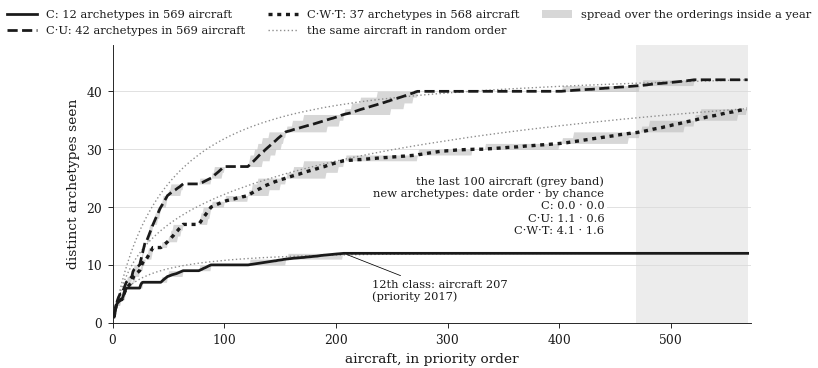

In [20]:
NAMES3 = {'A0': 'C', 'A0c': 'C·U', 'A1t': 'C·W·T'}
fig, ax = plt.subplots(figsize=(W, 3.4), constrained_layout=True)
plots.discovery_lines(ax, curve, NAMES3, cfg.analysis['discovery_tail'])
ax.set_xlabel('aircraft, in priority order'); ax.set_ylabel('distinct archetypes seen'); ax.set_ylim(0, 48)
h, l = ax.get_legend_handles_labels()
h += [Line2D([], [], color='#8c8c8c', linewidth=0.9, linestyle=(0, (1, 1.8))), Patch(facecolor='#bdbdbd', alpha=0.6, linewidth=0)]
l += ['the same aircraft in random order', 'spread over the orderings inside a year']
fig.legend(h, l, loc='outside upper center', ncol=3, fontsize=7.5, handlelength=2.6)
a0 = curve[curve['level'] == 'A0']
hit = a0[a0['archetypes (date order)'] >= a0['archetypes (date order)'].max() - 1e-9].iloc[0]
ax.annotate(f"12th class: aircraft {int(hit['aircraft'])}\n(priority {int(hit['priority year reached'])})", xy=(hit['aircraft'], 12),
            xytext=(hit['aircraft'] + 25, 5.5), fontsize=7.5, va='center', arrowprops=dict(arrowstyle='-', lw=0.5))
ei = est.set_index('level')
lines = ['the last 100 aircraft (grey band)', 'new archetypes: date order · by chance'] + [
    f"{NAMES3[s]}: {ei.loc[s, 'new in the last 100 aircraft']:.1f} · {ei.loc[s, 'new in the last 100, random order']:.1f}" for s in SETS3]
ax.text(0.77, 0.42, '\n'.join(lines), transform=ax.transAxes, ha='right', va='center', fontsize=7.5, linespacing=1.3, bbox=dict(fc='white', ec='none', pad=2))
plt.show()
save.figure(fig, cfg, 'q2', 'fig_09_discovery_curve', data=curve,
            caption='distinct archetypes seen as the aircraft accumulate in priority order, at three archetype sets, against a random order.',
            source='human labelling (class, wings, tilt, propulsor units) · PatSeer (priority date)',
            unit=f"unique aircraft with a priority year up to {cfg.analysis['last_complete_year']}, whose publication lag has run ({int(ei.loc['A0', 'aircraft'])} at C and C·U, {int(ei.loc['A1t', 'aircraft'])} at C·W·T, where one aircraft has no answer on a field)",
            read="Solid, dashed and dotted black lines: the distinct archetypes seen as aircraft are added in priority order, at C, C·U and C·W·T; the grey ribbon is the spread over the random orderings of the aircraft inside one priority year. The light dotted line of each set: the same aircraft in a fully random order, the reference for what accumulation alone gives. The grey band is the last 100 aircraft: the box prints the new archetypes the date order brought in that span against what a random 100 aircraft would have brought. A curve still climbing at the right edge means the space is still opening; a flat line means it is not producing new archetypes.")
plt.close(fig)

### 2.3 numbers

In [21]:
fs = split.set_index('archetype').loc[FOCUS]
top_key, top_share = frames.top_archetype_share(v, 'A0c', '2020-23', ds)
N3 = {
    'sm_zones_n': str(len(zones)), 'sm_zones_min': str(cfg.analysis['filer_panel_min_aircraft']), 'sm_zones_big_n': str(int((zones['aircraft'] >= cfg.analysis['filer_panel_min_aircraft']).sum())),
    'sm_cvt56_air': str(int(fs['aircraft'])), 'sm_cvt56_top': fs['largest filer'], 'sm_cvt56_top_n': str(int(fs['its aircraft'])),
    'sm_ch2_w1_n': str(winn['<= 2011']), 'sm_ch2_w2_n': str(winn['2012-15']),
    'sm_win_active_n': str(active), 'sm_win_active_share': pct(active / len(v)),
    'sm_z_core_n': str(len(core)), 'sm_z_core_share': pct(core['share 2016-23'].sum()),
    'sm_z_half_1619': str(half['2016-19'] + 1), 'sm_z_half_2023': str(half['2020-23'] + 1),
    'sm_cu_top_2023_share': pct(top_share),
    'sm_disc_a0_after': str(int(a0['aircraft'].max() - hit['aircraft'])),
    'sm_disc_a1t_new100': f"{ei.loc['A1t', 'new in the last 100 aircraft']:.1f}", 'sm_disc_a1t_exp100': f"{ei.loc['A1t', 'new in the last 100, random order']:.1f}",
}
numbers_check(N3)
print('also quoted in the text of 2.3 (not in the document\'s number list): rim', len(rim), 'archetypes,', pct(rim['share 2016-23'].sum()), 'of the 2016-23 aircraft;',
      '12th class at aircraft', int(hit['aircraft']), '(priority', int(hit['priority year reached']), '); C·U new in the last 100:', f"{ei.loc['A0c', 'new in the last 100 aircraft']:.1f}",
      'against', f"{ei.loc['A0c', 'new in the last 100, random order']:.1f}", ';', int(ei.loc['A1t', 'archetypes observed']), 'of', f"{ei.loc['A1t', 'Chao1']:.1f}", 'at C·W·T (', pct(ei.loc['A1t', 'share of richness found']), ');',
      'zones:', zones['zone'].value_counts().to_dict())

,name,notebook,document,match
0,sm_zones_n,33,33,yes
1,sm_zones_min,20,20,yes
2,sm_zones_big_n,11,11,yes
3,sm_cvt56_air,29,29,yes
4,sm_cvt56_top,Bell / Textron,Bell / Textron,yes
5,sm_cvt56_top_n,13,13,yes
6,sm_ch2_w1_n,63,63,yes
7,sm_ch2_w2_n,58,58,yes
8,sm_win_active_n,450,450,yes
9,sm_win_active_share,72 %,72 %,yes


also quoted in the text of 2.3 (not in the document's number list): rim 17 archetypes, 24 % of the 2016-23 aircraft; 12th class at aircraft 207 (priority 2017 ); C·U new in the last 100: 1.1 against 0.6 ; 37 of 41.0 at C·W·T ( 90 % ); zones: {'persistent': 25, 'new': 8}


## Overview: what matched

Every number the document quotes for chapter 2 (46) and every table, with the differences labelled.

In [22]:
allnum = pd.concat(NUMBERS, ignore_index=True)
n_doc = len(checks.reference_numbers('2'))
missing = checks.missing_numbers(dict.fromkeys(allnum['name']), '2')
print(f"numbers: {int((allnum['match'] == 'yes').sum())} of {len(allnum)} match the document; "
      f"{int(allnum['match'].str.startswith('expected').sum())} expected differences; {int((allnum['match'] == 'NO').sum())} failures; "
      f"{len(missing)} of the document's {n_doc} not computed here: {missing}")
overview = pd.DataFrame([c.iloc[0].to_dict() for c in CHECKS])
overview

numbers: 46 of 46 match the document; 0 expected differences; 0 failures; 0 of the document's 46 not computed here: []


,table,rows (notebook | document),cells compared,matched,expected differences,differences,status
0,a2_d3_selected_fields,8 | 8,40,40,0,0,match
1,la_duct_count,6 | 6,36,36,0,0,match
2,la_duct_conditional,6 | 6,66,66,0,0,match
3,la_archetype_levels,9 | 9,117,117,0,0,match
4,la_archetype_choice,9 | 9,9,9,0,0,match
5,la_archetype_levels_brief,4 | 4,28,28,0,0,match
6,la_zones,33 | 33,495,495,0,0,match
7,la_archetype_filer_split,11 | 11,66,66,0,0,match
8,la_discovery_curve,1706 | 1706,8530,8530,0,0,match
9,la_discovery_estimators,3 | 3,51,51,0,0,match


In [23]:
assert (allnum['match'] != 'NO').all(), allnum[allnum['match'] == 'NO']
assert not missing
assert (overview['differences'] == 0).all(), overview[overview['differences'] > 0]